# Analysing Air Quality and Its Link to Urban Factors

**DSAI501, Option B.**

This notebook estimates **same-hour reference carbon monoxide (CO, mg/m³)** using low-cost sensor responses, weather and calendar features. It is not a next-hour forecast. Urban traffic and land use are not measured here, so temporal patterns are proxies rather than causal evidence.

The workflow is: clean the data → build a baseline → create features → compare models → check errors → predict and export.

Run from the project folder. Outputs are saved in `artifacts/` and `figures/`.

In [1]:
from pathlib import Path
import json, sys, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from features import SENSORS, WEATHER, RAW_COLUMNS, prepare_features, predict_records

ROOT=Path.cwd()
assert (ROOT/'data/raw/AirQualityUCI.csv').exists(), 'Run in the project directory.'
for folder in ['artifacts','figures','data/processed']:(ROOT/folder).mkdir(exist_ok=True,parents=True)
pd.set_option('display.max_columns',30)
pd.set_option('display.precision',3)
plt.rcParams.update({'font.family':'DejaVu Serif','font.size':10,'figure.dpi':110,
                     'axes.spines.top':False,'axes.spines.right':False})
def savefig(name):
    plt.tight_layout()
    plt.savefig(ROOT/'figures'/name,dpi=180,bbox_inches='tight')
    plt.show()
print('Python',platform.python_version(),'| pandas',pd.__version__,'| scikit-learn',sklearn.__version__)


Python 3.12.14 | pandas 3.0.6 | scikit-learn 1.9.1


## 1 Data provenance and the raw-file audit

Source: Vito (2008), UCI Air Quality, DOI 10.24432/C59K5F, downloaded 15 October 2026. Keep the original ZIP and CSV unchanged. The repository describes hourly averages and identifies `-200` as missing. The raw file uses semicolons and decimal commas. Reading it as ordinary comma-separated data would corrupt the schema.

We count empty export rows separately from real observations and inspect the **actual timestamp range** rather than copying the repository's summary dates. Sensors are electrical responses, not pollutant concentrations. CO and NO₂ reference columns have different units.

In [2]:
raw_path=ROOT/'data/raw/AirQualityUCI.csv'
raw=pd.read_csv(raw_path,sep=';',decimal=',')
raw_shape=raw.shape
empty_rows=int(raw.isna().all(axis=1).sum())
empty_columns=raw.columns[raw.isna().all()].tolist()
df=raw.dropna(how='all').drop(columns=empty_columns).copy()
df['timestamp']=pd.to_datetime(df['Date']+' '+df['Time'],format='%d/%m/%Y %H.%M.%S',errors='coerce')
assert df.timestamp.notna().all(), 'Investigate invalid timestamps; do not silently drop them.'
duplicate_times=int(df.timestamp.duplicated().sum())
assert duplicate_times==0, 'Resolve repeated timestamps before splitting.'
numeric=[c for c in df.columns if c not in ['Date','Time','timestamp']]
sentinel_counts=(df[numeric]==-200).sum()
df[numeric]=df[numeric].replace(-200,np.nan)
df=df.sort_values('timestamp').reset_index(drop=True)
unexpected_negatives={c:int((df[c]<0).sum()) for c in numeric if c!='T'}
assert sum(unexpected_negatives.values())==0, unexpected_negatives
assert df.RH.dropna().between(0,100).all()
audit={'raw_rows':raw_shape[0],'raw_columns':raw_shape[1],'empty_rows':empty_rows,
       'empty_columns':empty_columns,'observations':len(df),'duplicate_timestamps':duplicate_times,
       'start':str(df.timestamp.min()),'end':str(df.timestamp.max()),
       'csv_sha256':hashlib.sha256(raw_path.read_bytes()).hexdigest()}
display(pd.Series(audit,name='Audit'))
missing=pd.DataFrame({'missing':df[numeric].isna().sum(),'percent':100*df[numeric].isna().mean(),
                      'sentinel_minus200':sentinel_counts}).sort_values('percent',ascending=False)
display(missing.round(2))
missing.to_csv(ROOT/'artifacts/missingness.csv')


raw_rows                                                             9471
raw_columns                                                            17
empty_rows                                                            114
empty_columns                                  [Unnamed: 15, Unnamed: 16]
observations                                                         9357
duplicate_timestamps                                                    0
start                                                 2004-03-10 18:00:00
end                                                   2005-04-04 14:00:00
csv_sha256              13277ae5d8581e80b7be09d47c7d3d06fe9b8e957078f2...
Name: Audit, dtype: object

,missing,percent,sentinel_minus200
NMHC(GT),8443,90.23,8443
CO(GT),1683,17.99,1683
NO2(GT),1642,17.55,1642
NOx(GT),1639,17.52,1639
PT08.S1(CO),366,3.91,366
C6H6(GT),366,3.91,366
PT08.S2(NMHC),366,3.91,366
PT08.S3(NOx),366,3.91,366
PT08.S4(NO2),366,3.91,366
PT08.S5(O3),366,3.91,366


## 2 Cleaning and target decisions

1. Remove only wholly empty export rows and columns. Valid high pollution readings are retained; an extreme value can be the event that matters most.
2. Convert every `-200` in numeric measurements to missing. Negative temperature is physically plausible and is retained.
3. Select **CO(GT)** as the observed reference target. Drop rows with missing target values for fitting and scoring. Imputing the target would manufacture ground truth and make validation misleading.
4. Exclude NMHC(GT), which is mostly missing. Also exclude all other reference analyzer concentrations, including C6H6(GT), NOx(GT) and NO2(GT), from model inputs. A low-cost monitoring system should not require another reference analyzer to estimate CO.
5. Use temperature and relative humidity, omitting absolute humidity to limit closely related weather inputs. Median imputation plus missingness indicators is fitted inside each training pipeline, never on the full dataset. We assess severe sensor outages separately and abstain in the demo when fewer than three sensors are available.
6. Do not interpolate pollutant gaps across time or across evaluation boundaries. Daily plots show observed means and retain missing dates. The missingness heatmap is a data-quality audit, not evidence that missing values are random.

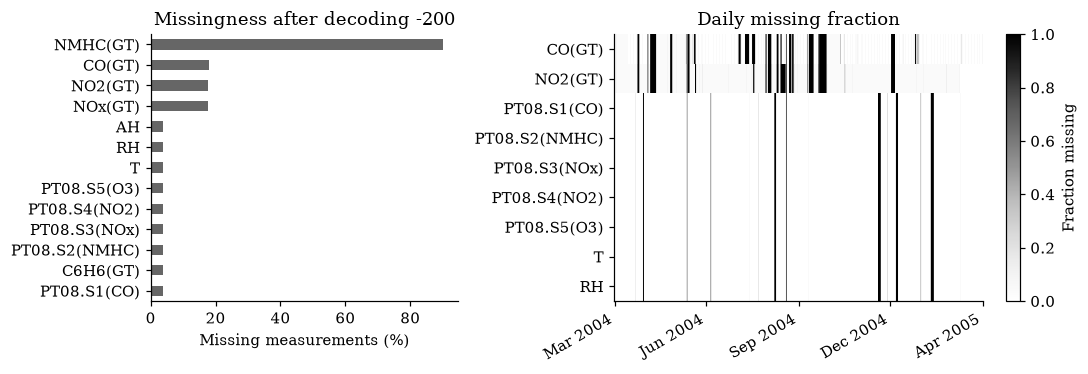

Target observed: 7674 | Excluded missing CO targets: 1683
Rows with all five sensors missing and observed CO: 330


In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5),gridspec_kw={'width_ratios':[1,1.5]})
missing['percent'].sort_values().plot.barh(ax=axes[0],color='0.4')
axes[0].set(xlabel='Missing measurements (%)',title='Missingness after decoding -200')
daily_missing=df.set_index('timestamp')[['CO(GT)','NO2(GT)']+SENSORS+WEATHER].isna().resample('D').mean()
im=axes[1].imshow(daily_missing.T,aspect='auto',cmap='Greys',vmin=0,vmax=1,interpolation='nearest')
axes[1].set_yticks(range(len(daily_missing.columns)),daily_missing.columns)
ticks=np.linspace(0,len(daily_missing)-1,5).astype(int)
axes[1].set_xticks(ticks,[daily_missing.index[i].strftime('%b %Y') for i in ticks],rotation=30,ha='right')
axes[1].set_title('Daily missing fraction');fig.colorbar(im,ax=axes[1],label='Fraction missing')
savefig('01_missingness.png')
observed=df.loc[df['CO(GT)'].notna()].copy()
print('Target observed:',len(observed),'| Excluded missing CO targets:',df['CO(GT)'].isna().sum())
print('Rows with all five sensors missing and observed CO:',observed[SENSORS].isna().all(axis=1).sum())


## 3 Split before exploratory modelling

Split the data by **whole calendar days**, using the first 60% of the observation dates for training, the next 20% for validation, and the last 20% for testing. A full day at each boundary is reserved as an embargo. This is stricter than scattering neighboring hourly readings across random splits.

The objective remains same-hour estimation. Chronological testing asks whether a calibration learned earlier transfers to later weather and sensor conditions; it does not convert this into a forecasting model. All feature exploration below uses training observations. The final target values remain unused until the selected approach is fixed.

In [4]:
days=np.sort(df.timestamp.dt.normalize().unique())
val_start=pd.Timestamp(days[int(.6*len(days))])
test_start=pd.Timestamp(days[int(.8*len(days))])
train=observed.loc[observed.timestamp<val_start-pd.Timedelta(days=1)].copy()
valid=observed.loc[(observed.timestamp>=val_start)&(observed.timestamp<test_start-pd.Timedelta(days=1))].copy()
test=observed.loc[observed.timestamp>=test_start].copy()
embargo=observed.loc[~observed.index.isin(train.index.union(valid.index).union(test.index))].copy()
assert train.timestamp.max()<valid.timestamp.min()<test.timestamp.min()
split_table=pd.DataFrame([{'split':name,'rows':len(block),'days':block.timestamp.dt.normalize().nunique(),
                           'start':str(block.timestamp.min()),'end':str(block.timestamp.max())}
                          for name,block in [('Training',train),('Validation',valid),('Test',test),('Embargo',embargo)]])
display(split_table)
split_table.to_csv(ROOT/'artifacts/splits.csv',index=False)


,split,rows,days,start,end
0,Training,4138,200,2004-03-10 18:00:00,2004-10-28 23:00:00
1,Validation,1694,74,2004-10-30 00:00:00,2005-01-14 23:00:00
2,Test,1796,79,2005-01-16 00:00:00,2005-04-04 14:00:00
3,Embargo,46,2,2004-10-29 00:00:00,2005-01-15 23:00:00


## 4 Explore two pollutants over time

CO is measured in mg/m³ and NO₂ in µg/m³, so they have separate axes rather than being compared numerically on one scale. Daily means smooth hourly noise, while the hourly panels examine recurring daily timing. Weekday/weekend comparisons are descriptive: traffic volumes, public holidays, wind and road closures are absent, so a weekday association cannot identify a traffic-policy effect.

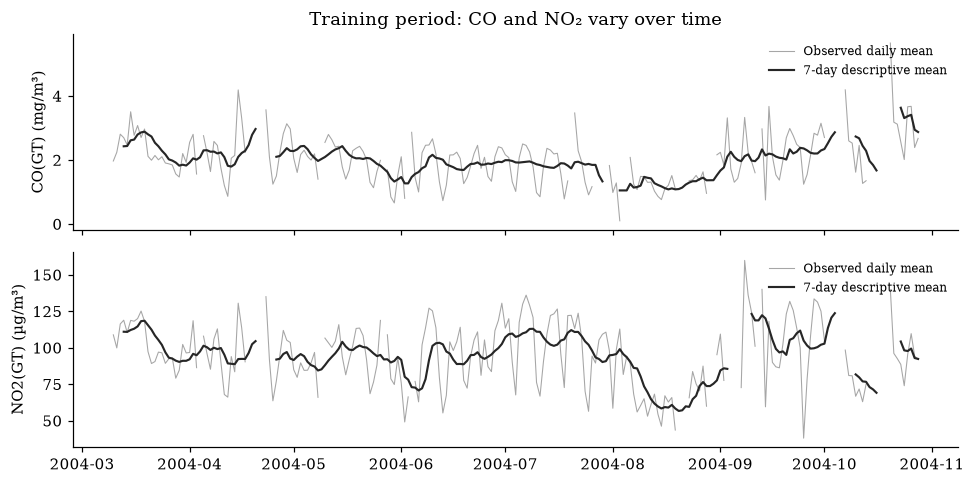

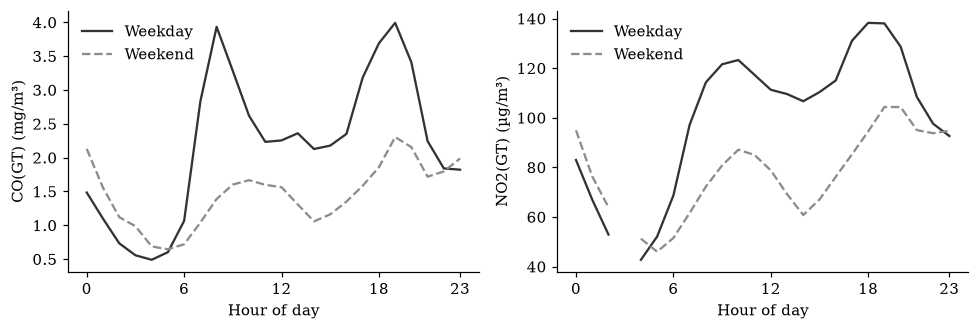

CO(GT)        NO2(GT)      
           mean count     mean count
day_type                            
Weekday   2.239  2939  101.564  3064
Weekend   1.473  1199   77.852  1130

hour
19    3.528
18    3.184
8     3.150
20    3.063
9     2.784
Name: CO(GT), dtype: float64

In [5]:
eda_train=df.loc[df.timestamp<val_start-pd.Timedelta(days=1)].copy()
train_daily=eda_train.set_index('timestamp')[['CO(GT)','NO2(GT)']].resample('D').mean()
fig,axes=plt.subplots(2,1,figsize=(9,4.5),sharex=True)
for ax,col,unit in zip(axes,['CO(GT)','NO2(GT)'],['mg/m³','µg/m³']):
    ax.plot(train_daily.index,train_daily[col],color='0.65',lw=.7,label='Observed daily mean')
    ax.plot(train_daily.index,train_daily[col].rolling(7,min_periods=4).mean(),color='0.15',lw=1.4,label='7-day descriptive mean')
    ax.set(ylabel=f'{col} ({unit})');ax.legend(frameon=False,fontsize=8,loc='upper right')
axes[0].set_title('Training period: CO and NO₂ vary over time')
savefig('02_two_pollutants_daily.png')
eda=eda_train.assign(hour=eda_train.timestamp.dt.hour,day_type=np.where(eda_train.timestamp.dt.dayofweek>=5,'Weekend','Weekday'))
hourly=eda.groupby(['day_type','hour'])[['CO(GT)','NO2(GT)']].mean()
fig,axes=plt.subplots(1,2,figsize=(9,3.1))
for ax,col,unit in zip(axes,['CO(GT)','NO2(GT)'],['mg/m³','µg/m³']):
    for group,style in [('Weekday','-'),('Weekend','--')]:
        values=hourly.loc[group,col];ax.plot(values.index,values.values,style,label=group,color='0.2' if group=='Weekday' else '0.55')
    ax.set(xlabel='Hour of day',ylabel=f'{col} ({unit})',xticks=[0,6,12,18,23]);ax.legend(frameon=False)
savefig('03_hourly_patterns.png')
day_summary=eda.groupby('day_type')[['CO(GT)','NO2(GT)']].agg(['mean','count'])
display(day_summary.round(3));display(eda.groupby('hour')['CO(GT)'].mean().sort_values(ascending=False).head(5))
day_summary.to_csv(ROOT/'artifacts/weekday_summary.csv')
hourly.to_csv(ROOT/'artifacts/hourly_patterns.csv')


## 5 Distribution, weather and unusual readings

Use numeric correlations as descriptive checks, not automatic feature-selection rules. Sensor responses overlap and may be cross-sensitive. A log-target experiment is motivated by right-skewed CO, but whether it improves absolute concentration errors must be checked on validation data. No outlier is deleted solely for being in the upper tail.

,CO(GT),NO2(GT),T,RH
count,4138.000,3860.000,4023.000,4023.000
mean,2.017,96.048,23.135,44.001
std,1.304,36.984,7.379,16.137
min,0.100,2.000,6.300,9.200
25%,1.000,68.000,17.800,30.750
50%,1.700,95.000,22.600,44.100
75%,2.700,120.000,27.700,56.200
max,9.500,233.000,44.600,83.200


PT08.S2(NMHC)    0.946
PT08.S1(CO)      0.903
PT08.S5(O3)      0.875
PT08.S4(NO2)     0.855
T                0.032
RH              -0.038
PT08.S3(NOx)    -0.739
Name: CO(GT), dtype: float64

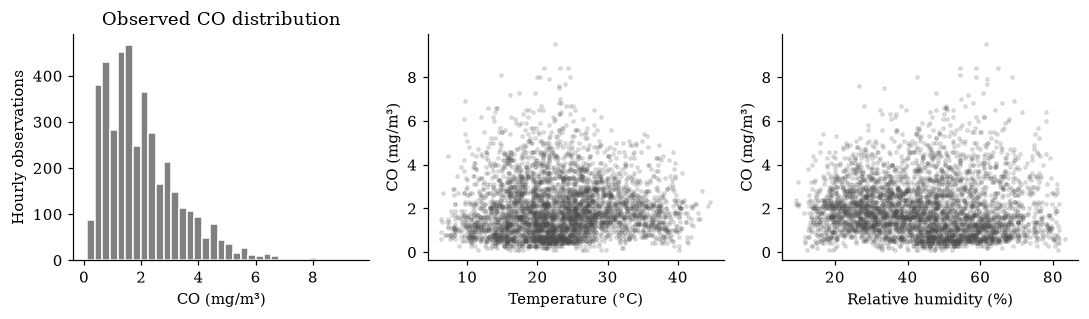

In [6]:
display(train[['CO(GT)','NO2(GT)','T','RH']].describe().round(3))
correlations=train[['CO(GT)']+SENSORS+WEATHER].corr()['CO(GT)'].drop('CO(GT)').sort_values(ascending=False)
display(correlations.round(3))
fig,axes=plt.subplots(1,3,figsize=(10,3.0))
axes[0].hist(train['CO(GT)'],bins=35,color='0.5',edgecolor='white');axes[0].set(xlabel='CO (mg/m³)',ylabel='Hourly observations',title='Observed CO distribution')
for ax,col,label in [(axes[1],'T','Temperature (°C)'),(axes[2],'RH','Relative humidity (%)')]:
    ax.scatter(train[col],train['CO(GT)'],s=5,alpha=.15,color='0.3');ax.set(xlabel=label,ylabel='CO (mg/m³)')
savefig('04_distribution_weather.png')


## 6 Feature engineering and training-only preprocessing

The raw linear benchmark uses the five sensor responses, temperature, humidity and a numeric hour. The engineered recipe replaces the discontinuous numeric hour with sine/cosine terms, adds annual sine/cosine seasonality, a weekend flag, weekday categories, temperature squared, and CO-sensor × humidity. Cycles keep 23:00 close to midnight. Temperature squared allows a curved association; the interaction tests whether the CO sensor's response depends on humidity. These are hypotheses to validate, not established physical laws.

Ridge controls overlapping features using an L2 penalty. Scaling is learned only from the fold's training rows. One-hot encoding handles weekday categories and ignores previously unseen categories safely. The weather/calendar-only ridge comparator tests how much predictive information exists without the sensor array. Other reference pollutants, the target and record identifiers never enter X.

Feature logic is in `features.py` so the demo and notebook share exactly the same recipe.

In [7]:
def make_model(regressor, X, strategy='median'):
    numeric_columns=X.select_dtypes(include=np.number).columns.tolist()
    categorical_columns=[c for c in X if c not in numeric_columns]
    numeric_pipeline=Pipeline([('impute',SimpleImputer(strategy=strategy,add_indicator=True)),('scale',StandardScaler())])
    categories=Pipeline([('impute',SimpleImputer(strategy='constant',fill_value='Missing')),
                         ('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
    preprocessor=ColumnTransformer([('numeric',numeric_pipeline,numeric_columns),('categories',categories,categorical_columns)],remainder='drop')
    return Pipeline([('prepare',preprocessor),('model',regressor)])

X_train=prepare_features(train);X_valid=prepare_features(valid)
y_train=train['CO(GT)'];y_valid=valid['CO(GT)']
assert 'CO(GT)' not in X_train and 'NO2(GT)' not in X_train
display(X_train.head(3));print('Engineered input columns:',X_train.columns.tolist())

# Use expanding training folds with a one-day gap.
train_days=np.sort(train.timestamp.dt.normalize().unique())
cv_folds=[];fold_rows=[]
for fraction in [.4,.6,.8]:
    boundary=pd.Timestamp(train_days[int(fraction*len(train_days))])
    end=pd.Timestamp(train_days[min(int((fraction+.2)*len(train_days)),len(train_days)-1)])+pd.Timedelta(days=1)
    fit_positions=np.flatnonzero(train.timestamp<boundary-pd.Timedelta(days=1))
    check_positions=np.flatnonzero((train.timestamp>=boundary)&(train.timestamp<end))
    assert train.iloc[fit_positions].timestamp.max()<train.iloc[check_positions].timestamp.min()-pd.Timedelta(hours=24)
    cv_folds.append((fit_positions,check_positions))
    fold_rows.append({'fit_rows':len(fit_positions),'check_rows':len(check_positions),'check_start':str(boundary),'check_end':str(end)})
display(pd.DataFrame(fold_rows))


,PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,hour_sin,hour_cos,year_sin,year_cos,weekend,temperature_squared,S1_x_humidity,weekday
0,1360.0,1046.0,1056.0,1692.0,1268.0,13.6,48.9,-1.000,-1.837e-16,0.927,0.374,0,184.96,665.040,2
1,1292.0,955.0,1174.0,1559.0,972.0,13.3,47.7,-0.966,2.588e-01,0.927,0.374,0,176.89,616.284,2
2,1402.0,939.0,1140.0,1555.0,1074.0,11.9,54.0,-0.866,5.000e-01,0.927,0.374,0,141.61,757.080,2


Engineered input columns: ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'hour_sin', 'hour_cos', 'year_sin', 'year_cos', 'weekend', 'temperature_squared', 'S1_x_humidity', 'weekday']


,fit_rows,check_rows,check_start,check_end
0,1632,970,2004-06-07 00:00:00,2004-07-18 00:00:00
1,2578,790,2004-07-17 00:00:00,2004-09-08 00:00:00
2,3347,768,2004-09-07 00:00:00,2004-10-29 00:00:00


## 7 Baseline, models and validation comparison

The housing demonstration uses a median baseline because its primary loss is MAE. Here the brief requires RMSE and R² and we select by **validation RMSE**, so the mean baseline is appropriate: the training mean minimizes constant squared error. We also report MAE in concentration units.

We compare ordinary linear regression, engineered ridge, log-CO ridge and random forest. Ridge alpha is chosen inside training folds from a small, fixed grid. The log model returns predictions to original units before scoring. The forest is a nonlinear comparator with a small predeclared depth/leaf grid. No model or hyperparameter is selected using the final test block. 

,Model,parameters,CV_RMSE
0,Engineered ridge,{'model__alpha': 1000.0},0.475
1,Log-target ridge,{'regressor__model__alpha': 1000.0},0.462
2,Weather-calendar ridge,{'model__alpha': 1000.0},1.160
3,Random forest,"{'model__max_depth': 8, 'model__min_samples_le...",0.335


,Model,Training_RMSE,MAE,RMSE,R2,recipe
0,Log-target ridge,0.363,0.546,0.906,0.728,engineered
1,Random forest,0.220,0.597,0.959,0.696,engineered
2,Engineered ridge,0.398,0.605,0.974,0.686,engineered
3,Raw linear regression,0.361,0.658,1.020,0.656,raw
4,Weather-calendar ridge,1.111,1.149,1.520,0.235,weather
5,Mean baseline,1.304,1.341,1.858,-0.142,engineered


Selected on validation RMSE: Log-target ridge


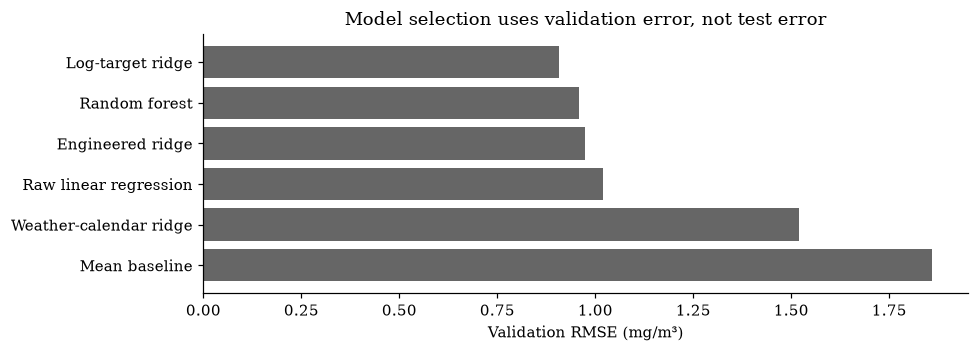

In [8]:
def metrics(actual,prediction):
    return {'MAE':mean_absolute_error(actual,prediction),'RMSE':float(np.sqrt(mean_squared_error(actual,prediction))),'R2':r2_score(actual,prediction)}

candidates={};validation_rows=[];search_rows=[]
def register(name,model,recipe):
    xt=prepare_features(train,recipe);xv=prepare_features(valid,recipe)
    train_score=metrics(y_train,model.predict(xt));score=metrics(y_valid,model.predict(xv))
    validation_rows.append({'Model':name,'Training_RMSE':train_score['RMSE'],**score,'recipe':recipe})
    candidates[name]=(model,recipe)

baseline=DummyRegressor(strategy='mean').fit(X_train,y_train)
register('Mean baseline',baseline,'engineered')
raw_X=prepare_features(train,'raw')
linear=make_model(LinearRegression(),raw_X).fit(raw_X,y_train)
register('Raw linear regression',linear,'raw')
alphas=[.1,1.,10.,100.,1000.]
for name,recipe,log_target in [('Engineered ridge','engineered',False),('Log-target ridge','engineered',True),('Weather-calendar ridge','weather',False)]:
    xt=prepare_features(train,recipe)
    estimator=make_model(Ridge(),xt)
    if log_target:
        estimator=TransformedTargetRegressor(regressor=estimator,func=np.log1p,inverse_func=np.expm1)
        grid={'regressor__model__alpha':alphas}
    else:grid={'model__alpha':alphas}
    search=GridSearchCV(estimator,grid,scoring='neg_root_mean_squared_error',cv=cv_folds,refit=True,n_jobs=1)
    search.fit(xt,y_train)
    search_rows.append({'Model':name,'parameters':str(search.best_params_),'CV_RMSE':-search.best_score_})
    register(name,search.best_estimator_,recipe)
forest_search=GridSearchCV(make_model(RandomForestRegressor(n_estimators=150,random_state=42,n_jobs=1),X_train),
    {'model__max_depth':[8,None],'model__min_samples_leaf':[3,10]},scoring='neg_root_mean_squared_error',cv=cv_folds,refit=True,n_jobs=1)
forest_search.fit(X_train,y_train)
search_rows.append({'Model':'Random forest','parameters':str(forest_search.best_params_),'CV_RMSE':-forest_search.best_score_})
register('Random forest',forest_search.best_estimator_,'engineered')
validation_results=pd.DataFrame(validation_rows).sort_values('RMSE').reset_index(drop=True)
selected_name=validation_results.iloc[0]['Model']
selected_model,selected_recipe=candidates[selected_name]
display(pd.DataFrame(search_rows));display(validation_results.round(4))
print('Selected on validation RMSE:',selected_name)
validation_results.to_csv(ROOT/'artifacts/validation_metrics.csv',index=False)
pd.DataFrame(search_rows).to_csv(ROOT/'artifacts/hyperparameter_search.csv',index=False)
fig,ax=plt.subplots(figsize=(9,3.3))
view=validation_results.sort_values('RMSE',ascending=False)
ax.barh(view.Model,view.RMSE,color='0.4');ax.set(xlabel='Validation RMSE (mg/m³)',title='Model selection uses validation error, not test error')
savefig('05_validation_comparison.png')


## 8 Sensitivity checks before final testing

Compare training-only mean versus median imputation on the already selected configuration. This is a sensitivity analysis rather than an additional round of model selection: the predefined median strategy remains fixed. Also inspect errors for validation rows with complete versus incomplete sensor/weather inputs. A flag can help a model handle a gap; it cannot reconstruct an unobserved pollution spike.

In [9]:
sensitivity=[]
for strategy in ['median','mean']:
    model=clone(selected_model)
    # Find the imputer inside each model pipeline.
    prefix='regressor__' if isinstance(model,TransformedTargetRegressor) else ''
    model.set_params(**{prefix+'prepare__numeric__impute__strategy':strategy})
    model.fit(prepare_features(train,selected_recipe),y_train)
    sensitivity.append({'Imputation':strategy,**metrics(y_valid,model.predict(prepare_features(valid,selected_recipe)))})
display(pd.DataFrame(sensitivity).round(4))
pd.DataFrame(sensitivity).to_csv(ROOT/'artifacts/imputation_sensitivity.csv',index=False)


,Imputation,MAE,RMSE,R2
0,median,0.546,0.906,0.728
1,mean,0.546,0.906,0.728


## 9 Final fit and untouched test evaluation

Freeze the selected model and hyperparameters. Refit preprocessing and model on the pre-test training-plus-validation rows, retaining the held-out boundary embargo. Only now prepare test targets for scoring. RMSE penalizes large concentration errors; R² compares squared error with predicting the test-set mean and may be negative. MAE reports typical absolute error. None is a percentage accuracy.

The exported model remains this pre-test fit so its test performance corresponds exactly to the delivered artifact. 

,Model,MAE,RMSE,R2
0,Mean baseline,1.121,1.392,-0.032
1,Log-target ridge,0.427,0.675,0.757


,n,MAE,mean_residual
concentration_segment,,,
Above training 90th percentile,210,0.874,0.480
Below training 90th percentile,1586,0.368,-0.204


,n,MAE,mean_residual
sensor_coverage,,,
Complete inputs,1711,0.388,-0.144
Some missing inputs,85,1.208,0.280


,timestamp,CO(GT),prediction,residual
8090,2005-02-10 20:00:00,8.4,2.663,5.737
8113,2005-02-11 19:00:00,7.1,2.750,4.350
8110,2005-02-11 16:00:00,7.1,2.802,4.298
7610,2005-01-21 20:00:00,4.9,8.872,-3.972
8111,2005-02-11 17:00:00,6.6,2.808,3.792


mean_test_residual                            -0.124
lag1_residual_correlation_adjacent_hours       0.819
adjacent_hour_pairs                         1760.000
negative_predictions                           0.000
Name: Residual diagnostics, dtype: float64

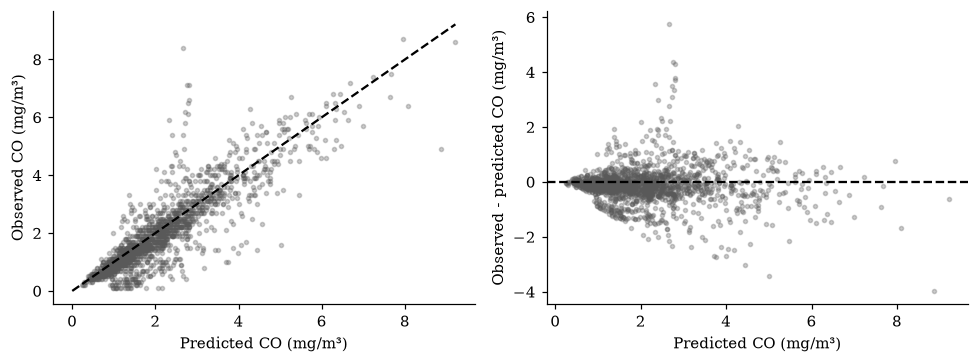

In [10]:
pretest=pd.concat([train,valid]).sort_values('timestamp')
final_model=clone(selected_model).fit(prepare_features(pretest,selected_recipe),pretest['CO(GT)'])
final_baseline=DummyRegressor(strategy='mean').fit(prepare_features(pretest),pretest['CO(GT)'])
X_test=prepare_features(test,selected_recipe);y_test=test['CO(GT)']
test_prediction=final_model.predict(X_test)
baseline_prediction=final_baseline.predict(prepare_features(test))
test_metrics=pd.DataFrame([{'Model':'Mean baseline',**metrics(y_test,baseline_prediction)},
                           {'Model':selected_name,**metrics(y_test,test_prediction)}])
display(test_metrics.round(4))
test_metrics.to_csv(ROOT/'artifacts/test_metrics.csv',index=False)
errors=test[['timestamp','CO(GT)']+SENSORS+WEATHER].copy()
errors['prediction']=test_prediction;errors['residual']=y_test-test_prediction;errors['absolute_error']=errors.residual.abs()
errors['sensor_coverage']=np.where(test[SENSORS+WEATHER].notna().all(axis=1),'Complete inputs','Some missing inputs')
high_threshold=float(y_train.quantile(.9))
errors['concentration_segment']=np.where(y_test>=high_threshold,'Above training 90th percentile','Below training 90th percentile')
segments=errors.groupby('concentration_segment').agg(n=('residual','size'),MAE=('absolute_error','mean'),mean_residual=('residual','mean'))
coverage=errors.groupby('sensor_coverage').agg(n=('residual','size'),MAE=('absolute_error','mean'),mean_residual=('residual','mean'))
display(segments.round(4));display(coverage.round(4));display(errors.nlargest(5,'absolute_error')[['timestamp','CO(GT)','prediction','residual']])
errors.to_csv(ROOT/'artifacts/test_predictions.csv',index=False);segments.to_csv(ROOT/'artifacts/segment_errors.csv');coverage.to_csv(ROOT/'artifacts/coverage_errors.csv')
consecutive=errors.timestamp.diff().eq(pd.Timedelta(hours=1))
lag1=float(errors.loc[consecutive,'residual'].corr(errors.residual.shift(1).loc[consecutive]))
diagnostics={'mean_test_residual':float(errors.residual.mean()),'lag1_residual_correlation_adjacent_hours':lag1,
             'adjacent_hour_pairs':int(consecutive.sum()),'negative_predictions':int((test_prediction<0).sum())}
display(pd.Series(diagnostics,name='Residual diagnostics'))
(ROOT/'artifacts/residual_diagnostics.json').write_text(json.dumps(diagnostics,indent=2))
fig,axes=plt.subplots(1,2,figsize=(9,3.4))
axes[0].scatter(test_prediction,y_test,s=7,alpha=.3,color='0.35');high=max(y_test.max(),test_prediction.max())
axes[0].plot([0,high],[0,high],'--',color='black');axes[0].set(xlabel='Predicted CO (mg/m³)',ylabel='Observed CO (mg/m³)')
axes[1].scatter(test_prediction,errors.residual,s=7,alpha=.3,color='0.35');axes[1].axhline(0,color='black',ls='--')
axes[1].set(xlabel='Predicted CO (mg/m³)',ylabel='Observed - predicted CO (mg/m³)')
savefig('06_test_diagnostics.png')


## 10 Which inputs does the fitted model use?

Permutation importance measures the increase in test RMSE when a predictor is shuffled, keeping the fitted model unchanged. It is a diagnostic of this model, not a causal effect or a feature-removal instruction. Correlated sensors can substitute for each other. Engineered terms and their ingredients are shuffled separately, which can create unrealistic combinations, so do not read the ranking as a definitive attribution. Any redesign based on these test diagnostics requires new evaluation data.



,feature,RMSE_increase,shuffle_std
1,PT08.S2(NMHC),2.508e-01,5.700e-03
4,PT08.S5(O3),7.370e-02,3.000e-03
7,hour_sin,4.650e-02,6.900e-03
0,PT08.S1(CO),4.570e-02,2.100e-03
3,PT08.S4(NO2),3.980e-02,2.500e-03
6,RH,2.250e-02,2.000e-03
5,T,1.530e-02,2.700e-03
2,PT08.S3(NOx),1.240e-02,2.500e-03
11,weekend,3.300e-03,5.000e-04
12,temperature_squared,2.900e-03,8.000e-04


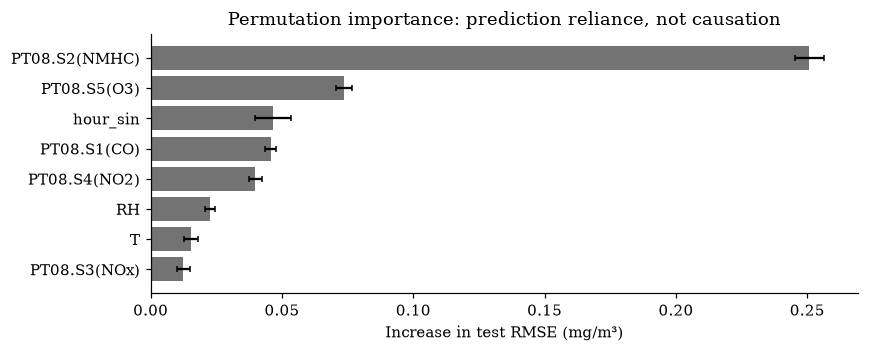

In [11]:
importance=permutation_importance(final_model,X_test,y_test,n_repeats=5,random_state=42,scoring='neg_root_mean_squared_error',n_jobs=1)
importance_table=pd.DataFrame({'feature':X_test.columns,'RMSE_increase':importance.importances_mean,'shuffle_std':importance.importances_std}).sort_values('RMSE_increase',ascending=False)
display(importance_table.round(4));importance_table.to_csv(ROOT/'artifacts/permutation_importance.csv',index=False)
top=importance_table.head(8).sort_values('RMSE_increase')
fig,ax=plt.subplots(figsize=(8,3.3));ax.barh(top.feature,top.RMSE_increase,xerr=top.shuffle_std,color='0.45',capsize=2)
ax.set(xlabel='Increase in test RMSE (mg/m³)',title='Permutation importance: prediction reliance, not causation')
savefig('07_permutation_importance.png')


## 11 Save the model, predict a case, and verify reloading

Export the fitted preprocessing together with the model, feature recipe and package versions. Use a real observed test row as a transparent demonstration; its target is displayed only after prediction. The model was already frozen before this row was inspected. The output is a research estimate, not a certified air-quality measurement or emergency alert.

The prediction wrapper adds an explicit sensor-coverage status.

In [12]:
bundle={'model':final_model,'model_name':selected_name,'recipe':selected_recipe,
        'raw_input_columns':RAW_COLUMNS,'target':'CO(GT)','units':'mg/m3','task':'same-hour reference concentration estimation',
        'training_end':str(pretest.timestamp.max()),'test_start':str(test.timestamp.min()),
        'versions':{'python':platform.python_version(),'scikit_learn':sklearn.__version__,'pandas':pd.__version__,'numpy':np.__version__},
        'policy':'abstain when fewer than three sensor responses are present; research use only'}
model_path=ROOT/'artifacts/air_quality_model.joblib';joblib.dump(bundle,model_path,compress=3)
metadata={k:v for k,v in bundle.items() if k!='model'}
(ROOT/'artifacts/model_metadata.json').write_text(json.dumps(metadata,indent=2))
sample=test.loc[test[SENSORS+WEATHER].notna().all(axis=1),RAW_COLUMNS].head(1).copy()
sample['timestamp']=sample.timestamp.astype(str)
sample.to_csv(ROOT/'artifacts/demo_input.csv',index=False)
demo=predict_records(bundle,sample);display(demo)
reloaded=joblib.load(model_path)
reloaded_demo=predict_records(reloaded,sample)
assert np.allclose(demo.predicted_CO_mg_m3,reloaded_demo.predicted_CO_mg_m3)
display(test.loc[sample.index,['timestamp','CO(GT)']])
demo.to_csv(ROOT/'artifacts/demo_prediction.csv',index=False)
no_sensors=sample.copy();no_sensors[SENSORS]=np.nan
assert predict_records(reloaded,no_sensors).status.str.contains('abstain').all()
print('Model reload parity and missing-sensor abstention checks passed.')
summary={'audit':audit,'target_missing':int(df['CO(GT)'].isna().sum()),'observed_targets':len(observed),
         'split_boundaries':{'validation':str(val_start),'test':str(test_start)},'selected_model':selected_name,
         'test_metrics':test_metrics.to_dict(orient='records'),'high_CO_threshold_training_p90':high_threshold,
         'hour_CO_peak':int(eda.groupby('hour')['CO(GT)'].mean().idxmax()),
         'training_weekday_CO':float(eda.loc[eda.day_type=='Weekday','CO(GT)'].mean()),
         'training_weekend_CO':float(eda.loc[eda.day_type=='Weekend','CO(GT)'].mean()),
         'training_weekday_NO2':float(eda.loc[eda.day_type=='Weekday','NO2(GT)'].mean()),
         'training_weekend_NO2':float(eda.loc[eda.day_type=='Weekend','NO2(GT)'].mean()),
         'minimum_prediction':float(test_prediction.min()),'model_file_bytes':model_path.stat().st_size}
(ROOT/'artifacts/results_summary.json').write_text(json.dumps(summary,indent=2))
df.to_csv(ROOT/'data/processed/air_quality_clean.csv',index=False)
print('Finished. Outputs are in artifacts/ and figures/.')


,timestamp,predicted_CO_mg_m3,status
7470,2005-01-16,2.811,research estimate


,timestamp,CO(GT)
7470,2005-01-16,3.8


Model reload parity and missing-sensor abstention checks passed.
Finished. Outputs are in artifacts/ and figures/.


## 12 Interpretation and limitations

Use `artifacts/results_summary.json` and the generated report for numerical findings from this execution. Policy should be tied to the measured daily/hourly patterns and prediction errors, not assumed before running the notebook. The dataset has one roadside site, historical measurements, unknown traffic volumes, no rainfall, no PM₂.₅, no wind, and no land-use or multi-city comparison. It cannot identify the effect of rainfall on particles or quantify a traffic-restriction benefit. Sensor drift, non-random outages and high-concentration underprediction limit reliability.

Recommended decision framework: use a low-cost estimate to prioritize reference-monitor checks and investigate recurring high-pollution periods. Validate on recent local reference data, establish an operational threshold with the relevant authority, and require a human-reviewed sensor-health check before any alert or traffic-policy action. A higher value than the training 90th percentile is a study segment, **not a health guideline**.

### References
Vito, S. (2008). *Air quality* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C59K5F


Scikit-learn developers. (n.d.). *User guide*. https://scikit-learn.org/stable/user_guide.html

See the report and source documentation for the complete APA reference list and AI declaration.